# Silver Line Phase 1: did jobs reachable by transit increase more near the stations?
**Question 1.** Jobs reachable within 30 minutes by transit, 2014 vs 2021 (Access Across America), Fairfax County, Virginia.

**Same setup as the `pt2_regression_population_and_housing_DiD.ipynb` notebook:** same 255 Fairfax tracts (ACS values > 0), tract shapes built from the 2014 block file, same treated (Phase 1) and control (five job centres) definitions.

**What is new here**
1. Block-level job access is matched across years, then rolled up to tracts (median of comparable blocks, minimum number of blocks per tract).
2. Descriptives and a difference-in-differences regression on the change in log job access (same model as Q3).
3. Change by distance band from the Phase 1 stations (tract level = main version, block level = robustness check).

**Data files** (in `data/` at the repo root):
- `data/access_across_america/dc_2014_transit/47900_tr_2014_0700-0859.shp` — 2014 block file. Despite the "dc" name it covers the whole Washington-Arlington-Alexandria metro region, so it includes Fairfax County (FIPS 51059); the code filters to Fairfax.
- `data/access_across_america/virginia_2021_transit/Virginia_51_transit_block_2021.csv`
- `data/dc_open_data/dc_metro_stations_regional.geojson` and `dc_metro_lines_regional.geojson`
- `data/ACS/B01003_population/` and `data/ACS/B25001_housing_units/` (2013 & 2019)

**How to run:** `Run > Run All Cells` in VS Code.

## 2. Imports and settings

In [32]:
# import libraries
import os, re, sys, glob, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.colors import TwoSlopeNorm
from shapely.ops import unary_union
warnings.filterwarnings("ignore")

In [33]:
# --- data file paths (relative to this notebook in analysis/) ---
DATA_DIR = "../data"
OUT_DIR  = "outputs_q1"
os.makedirs(OUT_DIR, exist_ok=True)

# Filter for Fairfax County, VA (FIPS 51059)
# (2014 DC data covers the whole Washington-Arlington-Alexandria metro region
F_2014_SHP   = os.path.join(DATA_DIR, "access_across_america", "dc_2014_transit", "47900_tr_2014_0700-0859.shp")
F_2021_CSV   = os.path.join(DATA_DIR, "access_across_america", "virginia_2021_transit", "Virginia_51_transit_block_2021.csv")
F_STATIONS   = os.path.join(DATA_DIR, "dc_open_data", "dc_metro_stations_regional.geojson")
F_LINES      = os.path.join(DATA_DIR, "dc_open_data", "dc_metro_lines_regional.geojson")
F_ACS_POP    = os.path.join(DATA_DIR, "ACS", "B01003_population")
F_ACS_HU     = os.path.join(DATA_DIR, "ACS", "B25001_housing_units")

STUDY_FIPS = "51059"                       # Fairfax County, VA
THR_30, THR_60 = 1800, 3600                # 2021 file stores thresholds in SECONDS (2014 file: 30 = minutes)

# --- choices you can change and should explain in the paper ---
STAT = "median"                            # how blocks are summarized within a tract: "median" or "mean"
MIN_BLOCKS_PER_TRACT = 3                   # tracts with fewer comparable blocks are left out
BAND_EDGES  = [0, 0.5, 1, 2, np.inf]       # distance bands in miles from the nearest Phase 1 station
BAND_LABELS = ["0-0.5 mi", "0.5-1 mi", "1-2 mi", "2+ mi"]

# --- map background ---
BACKGROUND = "tiles"                       # "tiles" or "outlines"
TILE_SOURCES = ["Esri.WorldGrayCanvas", "OpenStreetMap.Mapnik", "USGS.USTopo"]

# --- same design settings as Q3 ---
TREATED_MILES, CONTROL_RADIUS_MILES, NEAR_METRO_EXCLUDE_MILES = 1.0, 2.0, 1.5
PHASE1 = ["Wiehle-Reston East", "Spring Hill", "Greensboro", "Tysons", "McLean"]
PHASE2 = ["Reston Town Center", "Herndon", "Innovation Center", "Washington Dulles International Airport", "Loudoun Gateway", "Ashburn"]
CONTROL_CENTERS = {"Fair Oaks": (-77.35884, 38.86108), "Chantilly": (-77.44256, 38.88661),
                   "Fair Lakes": (-77.38697, 38.85812), "Braddock": (-77.35531, 38.83597),
                   "George Mason": (-77.31130, 38.83279)}
MI = 1609.344
BLUE, GRAY, PINK = "#08519c", "#7f7f7f", "#e6007e"
COUNTY_FIPS = {"Fairfax County": "51059", "Loudoun County": "51107", "Arlington County": "51013",
               "Prince William County": "51153", "Alexandria city": "51510", "Falls Church city": "51610",
               "Fairfax city": "51600", "Manassas city": "51683", "Manassas Park city": "51685",
               "District of Columbia": "11001"}

## 3. Keep the same tracts as Q3 (ACS values > 0)
The ACS tables are used **only** to reproduce the Q3 tract set (255 Fairfax tracts with population and housing > 0 in both years).

In [34]:
def read_acs(path):
    """Read an ACS file and return {tract_id: value} for Fairfax County tracts."""
    if path.endswith(".xlsx"):
        d = pd.read_excel(path, sheet_name="Data", header=None, dtype=str)
        pairs = [(d.iloc[0, j], d.iloc[2, j]) for j in range(1, d.shape[1])
                 if isinstance(d.iloc[0, j], str) and "estimate" in str(d.iloc[1, j]).lower()]
    else:
        d = pd.read_csv(path, dtype=str)
        d.columns = [c.strip() for c in d.columns]
        pairs = [(c, d.iloc[0][c]) for c in d.columns[1:] if c.endswith("!!Estimate")]
    out = {}
    for name, val in pairs:
        m = re.search(r"Census Tract ([\d.]+), Fairfax County", str(name))
        if m:
            out[f"51059{int(round(float(m.group(1)) * 100)):06d}"] = float(str(val).replace(",", ""))
    return out

pop13 = read_acs(os.path.join(DATA_DIR, "ACS", "B01003_population", "ACSDT5Y2013.B01003-2026-10-29T225439.csv"))
pop19 = read_acs(os.path.join(DATA_DIR, "ACS", "B01003_population", "ACSDT5Y2019.B01003-2026-10-29T225451.csv"))
hu13  = read_acs(os.path.join(DATA_DIR, "ACS", "B25001_housing_units", "ACSDT5Y2013.B25001-2026-11-10T025530.xlsx"))
hu19  = read_acs(os.path.join(DATA_DIR, "ACS", "B25001_housing_units", "ACSDT5Y2019.B25001-2026-11-10T025503.xlsx"))

acs = pd.DataFrame({"pop13": pop13, "pop19": pop19, "hu13": hu13, "hu19": hu19}).dropna()
acs = acs[(acs.pop13 > 0) & (acs.hu13 > 0)]
print(f"ACS tracts with all four values: {len(acs)}   (Q3 had 255)")

ACS tracts with all four values: 255   (Q3 had 255)


In [35]:
acs.head()

,pop13,pop19,hu13,hu19
51059415100,3692.0,3624.0,1271.0,1303.0
51059415200,3046.0,3016.0,1957.0,1877.0
51059415300,3865.0,3955.0,1516.0,1468.0
51059415401,5351.0,5103.0,2183.0,2172.0
51059415402,2889.0,3015.0,1140.0,1144.0


## 4. 2014 blocks (with 30-minute jobs), tract shapes, stations and the Silver Line
`tot_jobs` in the 2014 file is the number of jobs reachable within 30 minutes by transit (the file has a single threshold, 30). A value of -1 means no data.

In [36]:
b14 = gpd.read_file(F_2014_SHP, columns=["geoid", "threshold", "tot_jobs"])
b14["geoid"] = b14.geoid.astype(str)
b14 = b14[b14.geoid.str[:5] == STUDY_FIPS].to_crs(32618).copy()
assert (b14.threshold == 30).all(), "2014 file has thresholds other than 30 minutes; filter to 30"
b14["j14"] = b14.tot_jobs.where(b14.tot_jobs >= 0)          # -1 = no data
print(f"Fairfax blocks in 2014 file: {len(b14):,}")

# tract shapes: dissolve blocks (same as Q3), keep the same 255 tracts
tracts = b14[["geoid", "geometry"]].assign(t=b14.geoid.str[:11]).dissolve("t").drop(columns="geoid")
T = tracts.join(acs, how="inner")
print(f"Tracts joined to geometry: {len(T)}   (Q3 had 255)")

stations = gpd.read_file(F_STATIONS).to_crs(32618)
lines = gpd.read_file(F_LINES).to_crs(32618)
silver = lines[lines.NAME.str.lower() == "silver"]
s1 = stations[stations.NAME.isin(PHASE1)].drop_duplicates("NAME").set_index("NAME")
existing = stations[~stations.NAME.isin(PHASE1 + PHASE2)]
buf = lambda g, mi: unary_union(g.geometry.buffer(mi * MI).values)
g1 = buf(s1.reset_index(), TREATED_MILES)
g_existing = buf(existing, TREATED_MILES)
g_any = buf(stations, NEAR_METRO_EXCLUDE_MILES)
s1_union = unary_union(s1.geometry.values)

Fairfax blocks in 2014 file: 10,556
Tracts joined to geometry: 255   (Q3 had 255)


## 5. 2021 job access and matching the two years block by block
2021 values are in **seconds** (1800 = 30 min). A 0 at 30 minutes can be a real zero or a block with no resident workers (stored as 0). We call it "no data" if the block is also 0 at 60 minutes.

In [37]:
va_csv = F_2021_CSV
parts = []
for ch in pd.read_csv(va_csv, dtype={"geoid": str}, chunksize=500_000):
    ch = ch[ch.geoid.str.startswith(STUDY_FIPS) & ch.threshold.isin([THR_30, THR_60])]
    parts.append(ch[["geoid", "threshold", "weighted_average"]])
v = pd.concat(parts).pivot_table(index="geoid", columns="threshold", values="weighted_average", aggfunc="first")

b14["in_2021_file"] = b14.geoid.isin(v.index)
print(f"Share of 2014 Fairfax blocks whose GEOID is found in the 2021 file: {b14.in_2021_file.mean():.1%}")

b14["j21_30"] = b14.geoid.map(v[THR_30])
b14["j21_60"] = b14.geoid.map(v[THR_60])
b14["j21"] = b14.j21_30.where(b14.j21_60 > 0)                 # NaN = no resident workers (no data)
b14["valid"] = (b14.j14 > 0) & (b14.j21 > 0)                  # comparable in BOTH years

diag = pd.Series({
    "Fairfax blocks (2014 file)": len(b14),
    "2014: no data (-1)": int(b14.j14.isna().sum()),
    "2014: zero jobs reachable": int((b14.j14 == 0).sum()),
    "2021: not found in 2021 file": int((~b14.in_2021_file).sum()),
    "2021: no resident workers (0 at 30 and 60 min)": int((b14.in_2021_file & b14.j21.isna()).sum()),
    "2021: real zero (0 at 30 min, >0 at 60 min)": int((b14.j21 == 0).sum()),
    "Blocks zero in 2014 but positive in 2021 (dropped; possible Silver Line gains)": int(((b14.j14 == 0) & (b14.j21 > 0)).sum()),
    "Blocks positive in 2014 but zero in 2021 (dropped)": int(((b14.j14 > 0) & (b14.j21 == 0)).sum()),
    "COMPARABLE blocks (positive in both years)": int(b14.valid.sum()),
})
display(diag.to_frame("blocks"))
diag.to_frame("blocks").to_csv(os.path.join(OUT_DIR, "block_matching_diagnostics.csv"))

Share of 2014 Fairfax blocks whose GEOID is found in the 2021 file: 100.0%


,blocks
Fairfax blocks (2014 file),10556
2014: no data (-1),0
2014: zero jobs reachable,37
2021: not found in 2021 file,0
2021: no resident workers (0 at 30 and 60 min),3077
"2021: real zero (0 at 30 min, >0 at 60 min)",21
Blocks zero in 2014 but positive in 2021 (dropped; possible Silver Line gains),4
Blocks positive in 2014 but zero in 2021 (dropped),18
COMPARABLE blocks (positive in both years),7454


## 6. Roll comparable blocks up to tracts
Each tract gets one 2014 value and one 2021 value: the **median** (setting `STAT`) of its comparable blocks. Tracts with fewer than `MIN_BLOCKS_PER_TRACT` comparable blocks are dropped. This is an unweighted summary of blocks (a block with 5 residents counts the same as one with 500).

In [38]:
cb = b14[b14.valid].assign(t=lambda d: d.geoid.str[:11])
TJ = cb.groupby("t").agg(n_blocks=("geoid", "size"), j14=("j14", STAT), j21=("j21", STAT))
print(f"Tracts with at least one comparable block: {len(TJ)}")
TJ = TJ[TJ.n_blocks >= MIN_BLOCKS_PER_TRACT]
print(f"Tracts with at least {MIN_BLOCKS_PER_TRACT} comparable blocks: {len(TJ)}")
T = T.join(TJ, how="left")
T["pct"] = 100 * (T.j21 / T.j14 - 1)

Tracts with at least one comparable block: 258
Tracts with at least 3 comparable blocks: 254


## 7. Treated and control groups (same rules as Q3)

In [39]:
T["group"] = "other"
T.loc[T.intersects(g1) & ~T.intersects(g_existing), "group"] = "Phase 1"
circles = {k: gpd.GeoSeries(gpd.points_from_xy([x], [y]), crs=4326).to_crs(32618).iloc[0].buffer(CONTROL_RADIUS_MILES * MI)
           for k, (x, y) in CONTROL_CENTERS.items()}
ctl_ids, place_tracts = set(), {}
for k, c in circles.items():
    ids = T[T.intersects(c) & ~T.intersects(g_any) & (T.group != "Phase 1")].index
    place_tracts[k] = ids; ctl_ids |= set(ids)
T.loc[T.index.isin(ctl_ids), "group"] = "Control"

n_t, n_c = (T.group == "Phase 1").sum(), (T.group == "Control").sum()
print(f"Groups as in Q3:           treated {n_t}, control {n_c}   (Q3: 21 and 36)")
P = T[(T.group == "Phase 1") & T.j14.notna()].copy(); P["treat"] = 1
K = T[(T.group == "Control") & T.j14.notna()].copy(); K["treat"] = 0
print(f"After block-count filter:  treated {len(P)}, control {len(K)}")
A = pd.concat([P, K])
for d in (P, K, A):
    d["dy"] = np.log(d.j21 / d.j14)
P["station"] = [s1.geometry.distance(g.centroid).idxmin() for g in P.geometry]

Groups as in Q3:           treated 21, control 36   (Q3: 21 and 36)
After block-count filter:  treated 20, control 36


## 8. Table 1: descriptives
Tract-level job access (jobs reachable in 30 min) by group and year, plus the raw change.

In [40]:
rows = []
for g, lab in ((P, "Phase 1 station tracts"), (K, "Control place tracts")):
    for y, col in ((2014, "j14"), (2021, "j21")):
        x = g[col]
        rows.append({"Group": lab, "Year": y, "Tracts": len(x), "Mean": x.mean(), "Median": x.median(),
                     "SD": x.std(), "Min": x.min(), "Max": x.max()})
tab1 = pd.DataFrame(rows)
chg = pd.DataFrame({"Group": ["Phase 1 station tracts", "Control place tracts"],
                    "Tracts": [len(P), len(K)],
                    "Mean % change": [P.pct.mean(), K.pct.mean()],
                    "Median % change": [P.pct.median(), K.pct.median()],
                    "Tracts with an increase": [int((P.pct > 0).sum()), int((K.pct > 0).sum())]})
print('Tract-level job access summary')
display(tab1.round(1)); display(chg.round(1))

Tract-level job access summary


,Group,Year,Tracts,Mean,Median,SD,Min,Max
0,Phase 1 station tracts,2014,20,25113.2,20867.0,21430.8,385.0,84213.5
1,Phase 1 station tracts,2021,20,30202.8,24870.0,24097.2,430.0,97905.0
2,Control place tracts,2014,36,7221.5,3442.5,8820.6,91.5,31664.5
3,Control place tracts,2021,36,8068.0,4585.0,10200.6,96.0,34441.0


,Group,Tracts,Mean % change,Median % change,Tracts with an increase
0,Phase 1 station tracts,20,24.5,19.0,15
1,Control place tracts,36,21.8,7.8,22


## 9. Table 2: difference-in-differences
Same model as Q3: each tract's change in log job access regressed on a Phase 1 indicator (robust SE). Estimate is the extra % growth in job access near the stations relative to control places.

In [41]:
def did(df, kind="log"):
    d = df.copy()
    d["y"] = np.log(d.j21 / d.j14) if kind == "log" else d.j21 - d.j14
    m = smf.ols("y~treat", d).fit(cov_type="HC1")
    b, (lo, hi), p = m.params["treat"], m.conf_int().loc["treat"], m.pvalues["treat"]
    return (100 * (np.exp(b) - 1), 100 * (np.exp(lo) - 1), 100 * (np.exp(hi) - 1), p) if kind == "log" else (b, lo, hi, p)

top2_all = A.dy.nlargest(2).index
top2_p1 = P.dy.nlargest(2).index
specs = [("DiD, % change above control places (log)", A, "log", "%"),
         ("DiD, extra jobs reachable per tract (levels)", A, "lvl", "jobs"),
         ("DiD (log) without the 2 largest-gain tracts overall", A.drop(top2_all), "log", "%"),
         ("DiD (log) without the 2 largest-gain Phase 1 tracts", A.drop(top2_p1), "log", "%")]
rows = []
for name, df, kind, unit in specs:
    e, lo, hi, p = did(df, kind)
    rows.append({"Specification": name, "Unit": unit, "Estimate": e, "CI low": lo, "CI high": hi, "p-value": p, "Tracts": len(df)})
tab2 = pd.DataFrame(rows)

rows = []
for stn, g in list(P.groupby("station")) + [("All Phase 1 tracts", P)]:
    e, lo, hi, p = did(pd.concat([g, K]))
    rows.append({"Station (nearest)": stn, "Tracts": len(g), "Median % change": g.pct.median(),
                 "DiD %": e, "95% CI": f"{lo:.1f} to {hi:.1f}", "p": p})
tab3 = pd.DataFrame(rows)

rows = []
for k, ids in place_tracts.items():
    q = T.loc[ids].dropna(subset=["pct"])
    rows.append({"Control place": k, "Tracts used": len(q), "Median 2014": q.j14.median(), "Median 2021": q.j21.median(),
                 "Median % change": q.pct.median()})
tab4 = pd.DataFrame(rows)

print('Tract-level change in log job access (difference-in-differences) estimates')
print('Estimate = extra percent growth in job access relative to control areas')
display(tab2.round(3)); display(tab3.round(3)); display(tab4.round(1))

Tract-level change in log job access (difference-in-differences) estimates
Estimate = extra percent growth in job access relative to control areas


,Specification,Unit,Estimate,CI low,CI high,p-value,Tracts
0,"DiD, % change above control places (log)",%,8.398,-9.708,30.135,0.387,56
1,"DiD, extra jobs reachable per tract (levels)",jobs,4243.089,1840.714,6645.464,0.001,56
2,DiD (log) without the 2 largest-gain tracts ov...,%,15.681,-1.589,35.983,0.077,54
3,DiD (log) without the 2 largest-gain Phase 1 t...,%,2.729,-13.521,22.031,0.759,54


,Station (nearest),Tracts,Median % change,DiD %,95% CI,p
0,Greensboro,3,-3.849,-12.013,-24.1 to 2.0,0.089
1,McLean,3,24.240,-7.830,-37.8 to 36.5,0.684
2,Spring Hill,3,11.688,-1.243,-29.4 to 38.1,0.942
3,Tysons,2,36.920,22.369,-5.3 to 58.1,0.123
4,Wiehle-Reston East,9,31.318,23.164,-0.3 to 52.2,0.053
5,All Phase 1 tracts,20,18.976,8.398,-9.7 to 30.1,0.387


,Control place,Tracts used,Median 2014,Median 2021,Median % change
0,Fair Oaks,16,8492.5,7869.5,12.5
1,Chantilly,11,4332.0,4805.5,10.9
2,Fair Lakes,17,5389.0,6619.0,8.0
3,Braddock,12,10194.5,11235.0,8.6
4,George Mason,11,2898.0,1757.0,-2.2


## 10. Change by distance from the Phase 1 stations
**Main version (tract level):** each tract is assigned to a band by the distance from its centroid to the nearest Phase 1 station. Tracts that touch the 1-mile ring around a pre-existing Metro station are excluded, as in Q3.
**Robustness check (block level):** the same bands using each block's centre point. Control places are shown as a reference row.

In [42]:
# tract level
Tb = T[T.j14.notna() & ~T.intersects(g_existing)].copy()
Tb["d_mi"] = Tb.geometry.centroid.distance(s1_union) / MI
Tb["band"] = pd.cut(Tb.d_mi, BAND_EDGES, labels=BAND_LABELS, right=False, include_lowest=True)
bt = Tb.groupby("band", observed=True).agg(Tracts=("pct", "size"), Median_2014=("j14", "median"), Median_2021=("j21", "median"),
                            Median_pct_change=("pct", "median"), Mean_pct_change=("pct", "mean")).reset_index()
bt["band"] = bt["band"].astype(str)
bt.loc[len(bt)] = ["Control places", len(K), K.j14.median(), K.j21.median(), K.pct.median(), K.pct.mean()]
bt.insert(0, "Level", "Tract")

# block level (robustness)
pts = b14[b14.valid].copy()
pts["geometry"] = pts.geometry.representative_point()
ctl_zone = unary_union([c for c in circles.values()])
pts_ctl = pts[pts.within(ctl_zone) & ~pts.within(g_any)]
pts = pts[~pts.within(g_existing)].copy()
pts["pct_chg"] = 100 * (pts.j21 / pts.j14 - 1)
pts["d_mi"] = pts.geometry.distance(s1_union) / MI
pts["band"] = pd.cut(pts.d_mi, BAND_EDGES, labels=BAND_LABELS, right=False, include_lowest=True)
bb = pts.groupby("band", observed=True).agg(Tracts=("pct_chg", "size"), Median_2014=("j14", "median"), Median_2021=("j21", "median"),
                             Median_pct_change=("pct_chg", "median"), Mean_pct_change=("pct_chg", "mean")).reset_index()
pc = 100 * (pts_ctl.j21 / pts_ctl.j14 - 1)
bb["band"] = bb["band"].astype(str)
bb.loc[len(bb)] = ["Control places", len(pts_ctl), pts_ctl.j14.median(), pts_ctl.j21.median(), pc.median(), pc.mean()]
bb.insert(0, "Level", "Block")
bb = bb.rename(columns={"Tracts": "Units"}); bt = bt.rename(columns={"Tracts": "Units"})
tab5 = pd.concat([bt, bb], ignore_index=True)

print('Change in job access by distance band from Phase 1 stations (tracts and blocks)')
display(tab5.round(1))

Change in job access by distance band from Phase 1 stations (tracts and blocks)


,Level,band,Units,Median_2014,Median_2021,Median_pct_change,Mean_pct_change
0,Tract,0-0.5 mi,4,28479.0,40788.8,35.3,36.1
1,Tract,0.5-1 mi,5,40257.0,47131.0,20.9,28.7
2,Tract,1-2 mi,14,17235.5,20221.2,27.4,45.7
3,Tract,2+ mi,178,4153.5,4026.0,0.5,9.7
4,Tract,Control places,36,3442.5,4585.0,7.8,21.8
5,Block,0-0.5 mi,28,42578.5,74801.0,50.4,80.3
6,Block,0.5-1 mi,163,26428.0,32848.0,17.7,387.3
7,Block,1-2 mi,505,11702.0,14661.0,17.7,142.9
8,Block,2+ mi,6214,3692.0,3846.0,2.3,70.7
9,Block,Control places,782,4502.0,6783.0,15.0,195.2


## 11. Map helpers (open-source background)

In [43]:
Tm = T.to_crs(3857)
P_m, K_m = Tm.loc[P.index], Tm.loc[K.index]
s1_m, st_m, silver_m = s1.to_crs(3857), stations.to_crs(3857), silver.to_crs(3857)
county_m = gpd.GeoSeries([Tm.geometry.union_all() if hasattr(Tm.geometry, "union_all") else Tm.unary_union], crs=3857)
to_m = lambda g: gpd.GeoSeries([g], crs=32618).to_crs(3857).iloc[0]
rings_m = {r: to_m(buf(s1.reset_index(), r)) for r in (0.5, 1.0)}
circles_m = {k: to_m(c) for k, c in circles.items()}
centres_m = {k: to_m(gpd.GeoSeries(gpd.points_from_xy([v[0]], [v[1]]), crs=4326).to_crs(32618).iloc[0]) for k, v in CONTROL_CENTERS.items()}
TILES_OK = {"state": BACKGROUND == "tiles", "credit": ""}

def _provider(name):
    import contextily as cx
    src = cx.providers
    for part in name.split("."):
        src = src[part]
    return src

def add_background(ax, xlim, ylim):
    """Open-source background: keyless tiles if reachable, otherwise tract and county outlines."""
    ax.set_xlim(xlim); ax.set_ylim(ylim); ax.set_aspect("equal")
    if TILES_OK["state"]:
        try:
            import contextily as cx
        except ImportError:
            cx = None; TILES_OK["state"] = False
        for name in (TILE_SOURCES if cx else []):
            try:
                src = _provider(name)
                if hasattr(src, "requires_token") and src.requires_token():
                    print(f"Skipping {name}: needs an API key"); continue
                cx.add_basemap(ax, crs="EPSG:3857", source=src, attribution=False, zoom="auto")
                ax.set_xlim(xlim); ax.set_ylim(ylim)
                TILES_OK["credit"] = "Basemap: " + re.sub(r"<[^>]+>|&copy;", "", str(src.get("attribution", name))).replace("  ", " ").strip()
                return
            except Exception as e:
                print(f"Tiles from {name} unavailable ({type(e).__name__}); trying the next source.")
        TILES_OK["state"] = False
        print("No keyless tiles could be downloaded -> using tract and county outlines instead.")
    ax.set_facecolor("#f3f3f1")
    Tm.boundary.plot(ax=ax, color="#bdbdbd", lw=.4, zorder=1)
    gpd.GeoSeries(county_m.boundary).plot(ax=ax, color="#7a7a7a", lw=1.0, zorder=1)

def credit(fig, extra=""):
    txt = (TILES_OK["credit"] if TILES_OK["state"] else "Background: census tract outlines (2010) from the Access Across America block file") + extra
    fig.text(0.5, 0.005, txt, ha="center", va="bottom", fontsize=8, color="#555555")

def pad_bounds(b, f=0.06, ratio=None):
    w, h = b[2] - b[0], b[3] - b[1]; xl, xr, yb, yt = b[0] - w * f, b[2] + w * f, b[1] - h * f, b[3] + h * f
    if ratio:
        cx_, cy_, W = (xl + xr) / 2, (yb + yt) / 2, xr - xl
        H = W / ratio
        if (yt - yb) > H:
            H = yt - yb; W = H * ratio
        xl, xr, yb, yt = cx_ - W / 2, cx_ + W / 2, cy_ - H / 2, cy_ + H / 2
    return (xl, xr), (yb, yt)

def halo(): return [pe.withStroke(linewidth=3, foreground="white")]

def draw_stations(ax, labels=True, offsets=None):
    silver_m.plot(ax=ax, color=PINK, lw=3.2, zorder=6)
    for r, ls in ((0.5, "-"), (1.0, "--")):
        gpd.GeoSeries([rings_m[r]], crs=3857).boundary.plot(ax=ax, color="k", lw=1.3, ls=ls, zorder=7)
    s1_m.plot(ax=ax, color="white", edgecolor=PINK, linewidth=2.4, markersize=55, zorder=8)
    if labels:
        offsets = offsets or {}
        for n, r in s1_m.iterrows():
            ax.annotate(n, (r.geometry.x, r.geometry.y), xytext=offsets.get(n, (0, 12)), textcoords="offset points", ha="center",
                        fontsize=9, fontweight="bold", zorder=10, path_effects=halo())

## 12. Figure 1: study area

In [44]:
fig, ax = plt.subplots(figsize=(13, 8.5))
xl, yl = pad_bounds(unary_union([P_m.geometry.union_all() if hasattr(P_m.geometry, "union_all") else P_m.unary_union, *circles_m.values()]).bounds, 0.05, 1.5)
add_background(ax, xl, yl)
Tm.boundary.plot(ax=ax, color="#9a9a9a", lw=.35, zorder=2)
K_m.plot(ax=ax, color="#6b7a99", alpha=.40, edgecolor="#4a5875", linewidth=.6, zorder=3)
P_m.plot(ax=ax, color=PINK, alpha=.32, edgecolor=PINK, linewidth=.9, zorder=3)
for k, c in circles_m.items():
    gpd.GeoSeries([c], crs=3857).boundary.plot(ax=ax, color="#222", lw=1.4, ls="--", zorder=7)
    ax.plot(centres_m[k].x, centres_m[k].y, "k*", ms=11, zorder=9)
    ax.annotate(k, (centres_m[k].x, centres_m[k].y), xytext=(0, 12), textcoords="offset points", ha="center", fontsize=9, fontweight="bold", zorder=10, path_effects=halo())
draw_stations(ax, offsets={"Wiehle-Reston East": (0, -20), "Spring Hill": (-48, 14), "Greensboro": (-55, -8), "Tysons": (0, -26), "McLean": (28, 16)})
ax.set_xlim(xl); ax.set_ylim(yl); ax.axis("off")
ax.legend(handles=[Patch(fc=PINK, alpha=.4, ec=PINK, label=f"Phase 1 station tracts (n={len(P)})"),
                   Patch(fc="#6b7a99", alpha=.5, ec="#4a5875", label=f"Control place tracts (n={len(K)})"),
                   Line2D([], [], color=PINK, lw=3, label="Silver Line"),
                   Line2D([], [], marker="o", mfc="w", mec=PINK, mew=2.2, ls="", label="Phase 1 stations (opened Jul 2014)"),
                   Line2D([], [], color="k", lw=1.3, label="0.5 mile / 1 mile (dashed) from Phase 1 stations"),
                   Line2D([], [], color="#222", lw=1.4, ls="--", marker="*", mfc="k", label="2-mile circle around control place centre")],
          loc="lower left", fontsize=9, frameon=True, framealpha=.92)
ax.set_title("Study area: Phase 1 station tracts and no-Metro control places, Fairfax County", fontsize=13, fontweight="bold", loc="left")
credit(fig); fig.tight_layout(rect=(0, 0.02, 1, 1)); fig.savefig(os.path.join(OUT_DIR, "fig1_study_area_map.png"), dpi=140, bbox_inches="tight"); plt.close(fig)

Tiles from Esri.WorldGrayCanvas unavailable (SSLError); trying the next source.
Tiles from OpenStreetMap.Mapnik unavailable (SSLError); trying the next source.
Tiles from USGS.USTopo unavailable (SSLError); trying the next source.
No keyless tiles could be downloaded -> using tract and county outlines instead.


## 13. Figure 2: change in job access map

In [45]:
BR = [-np.inf, -50, -25, -10, 0, 10, 25, 50, np.inf]
COL = ["#4d4d4d", "#969696", "#d9d9d9", "#f5f5f5", "#d6e8f7", "#6baed6", "#08519c", "#04336c"]
LAB = ["below -50", "-50 to -25", "-25 to -10", "-10 to 0", "0 to +10", "+10 to +25", "+25 to +50", "above +50"]
xl, yl = pad_bounds(P_m.total_bounds, 0.04, 1.55)
fig, ax = plt.subplots(figsize=(13, 8.4))
add_background(ax, xl, yl)
cls = pd.cut(P.pct, BR, labels=False)
for i, c in enumerate(COL):
    q = P_m[(cls == i).values]
    if len(q): q.plot(ax=ax, color=c, alpha=.82, edgecolor="#444", linewidth=.8, zorder=3)
draw_stations(ax, offsets={"Wiehle-Reston East": (0, -22), "Spring Hill": (-55, 14), "Greensboro": (-62, -6), "Tysons": (4, -26), "McLean": (30, 16)})
for idx, r in P_m.iterrows():
    pt = r.geometry.representative_point()
    if xl[0] < pt.x < xl[1] and yl[0] < pt.y < yl[1]:
        ax.annotate(f"{P.loc[idx, 'pct']:+.0f}", (pt.x, pt.y), ha="center", va="center", fontsize=8, zorder=9, path_effects=halo())
ax.set_xlim(xl); ax.set_ylim(yl); ax.axis("off")
ax.set_title("Change in jobs reachable by transit (30 min), 2014 to 2021: Phase 1 station tracts", fontsize=13, fontweight="bold")
ax.legend(handles=[Patch(fc=c, ec="#777", label=l) for c, l in zip(COL, LAB)], loc="upper center", bbox_to_anchor=(.5, -.01), ncol=4, frameon=False,
          fontsize=9, title="Percentage change in jobs reachable (blue = increase, gray = decrease); numbers = % per tract")
credit(fig); fig.tight_layout(rect=(0, 0.02, 1, 1)); fig.savefig(os.path.join(OUT_DIR, "fig2_job_access_change_map.png"), dpi=130, bbox_inches="tight"); plt.close(fig)

## 14. Figure 3: distance bands and DiD estimates

In [46]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5.2), gridspec_kw=dict(width_ratios=[1, 1, 1.25]))
for a, lvl in zip(ax[:2], ["Tract", "Block"]):
    d = tab5[tab5.Level == lvl]
    bands = d[d.band != "Control places"]
    ctl = d[d.band == "Control places"].Median_pct_change.iloc[0]
    a.bar(bands.band.astype(str), bands.Median_pct_change, color=BLUE)
    a.axhline(ctl, color=GRAY, ls="--", lw=2, label=f"Control places ({ctl:.1f}%)")
    a.axhline(0, color="k", lw=.8)
    for i, (_, r) in enumerate(bands.iterrows()):
        a.annotate(f"n={int(r.Units)}", (i, r.Median_pct_change), ha="center", va="bottom", fontsize=8)
    a.set_title(f"{lvl}-level: median % change by distance to nearest Phase 1 station", loc="left", fontsize=10, fontweight="bold")
    a.spines[["top", "right"]].set_visible(False); a.grid(axis="y", alpha=.25); a.legend(frameon=False, fontsize=9, loc="upper right")
a = ax[2]; Z = tab2[tab2.Unit == "%"].reset_index(drop=True); labs = []
for i, (_, r) in enumerate(Z.iterrows()):
    a.plot([r["CI low"], r["CI high"]], [i, i], color=BLUE, lw=2.5); a.plot(r.Estimate, i, "o", color=BLUE, ms=8)
    a.annotate(f"{r.Estimate:+.1f}%  (p={r['p-value']:.2f})", (r["CI high"], i), xytext=(6, -3), textcoords="offset points", fontsize=8.5)
    labs.append(r.Specification.replace("DiD (log) ", "").replace("DiD, ", ""))
a.axvline(0, color="k", lw=.9); a.set_yticks(range(len(Z))); a.set_yticklabels(labs, fontsize=9); a.invert_yaxis()
a.set_xlabel("DiD estimate: extra % growth in job access vs control places (95% CI)")
a.set_title("Difference-in-differences estimates", loc="left", fontweight="bold")
a.spines[["top", "right"]].set_visible(False); a.grid(axis="x", alpha=.25); a.set_xlim(a.get_xlim()[0], a.get_xlim()[1] + 25)
fig.text(0.01, 0.0, "Job access = jobs reachable within 30 minutes by transit (Access Across America). Tract values are the median of comparable blocks.", fontsize=8, color="#555")
fig.tight_layout(rect=(0, 0.02, 1, 1)); fig.savefig(os.path.join(OUT_DIR, "fig3_distance_bands_and_did.png"), dpi=130, bbox_inches="tight"); plt.close(fig)

## 15. View the results

fig1_study_area_map.png


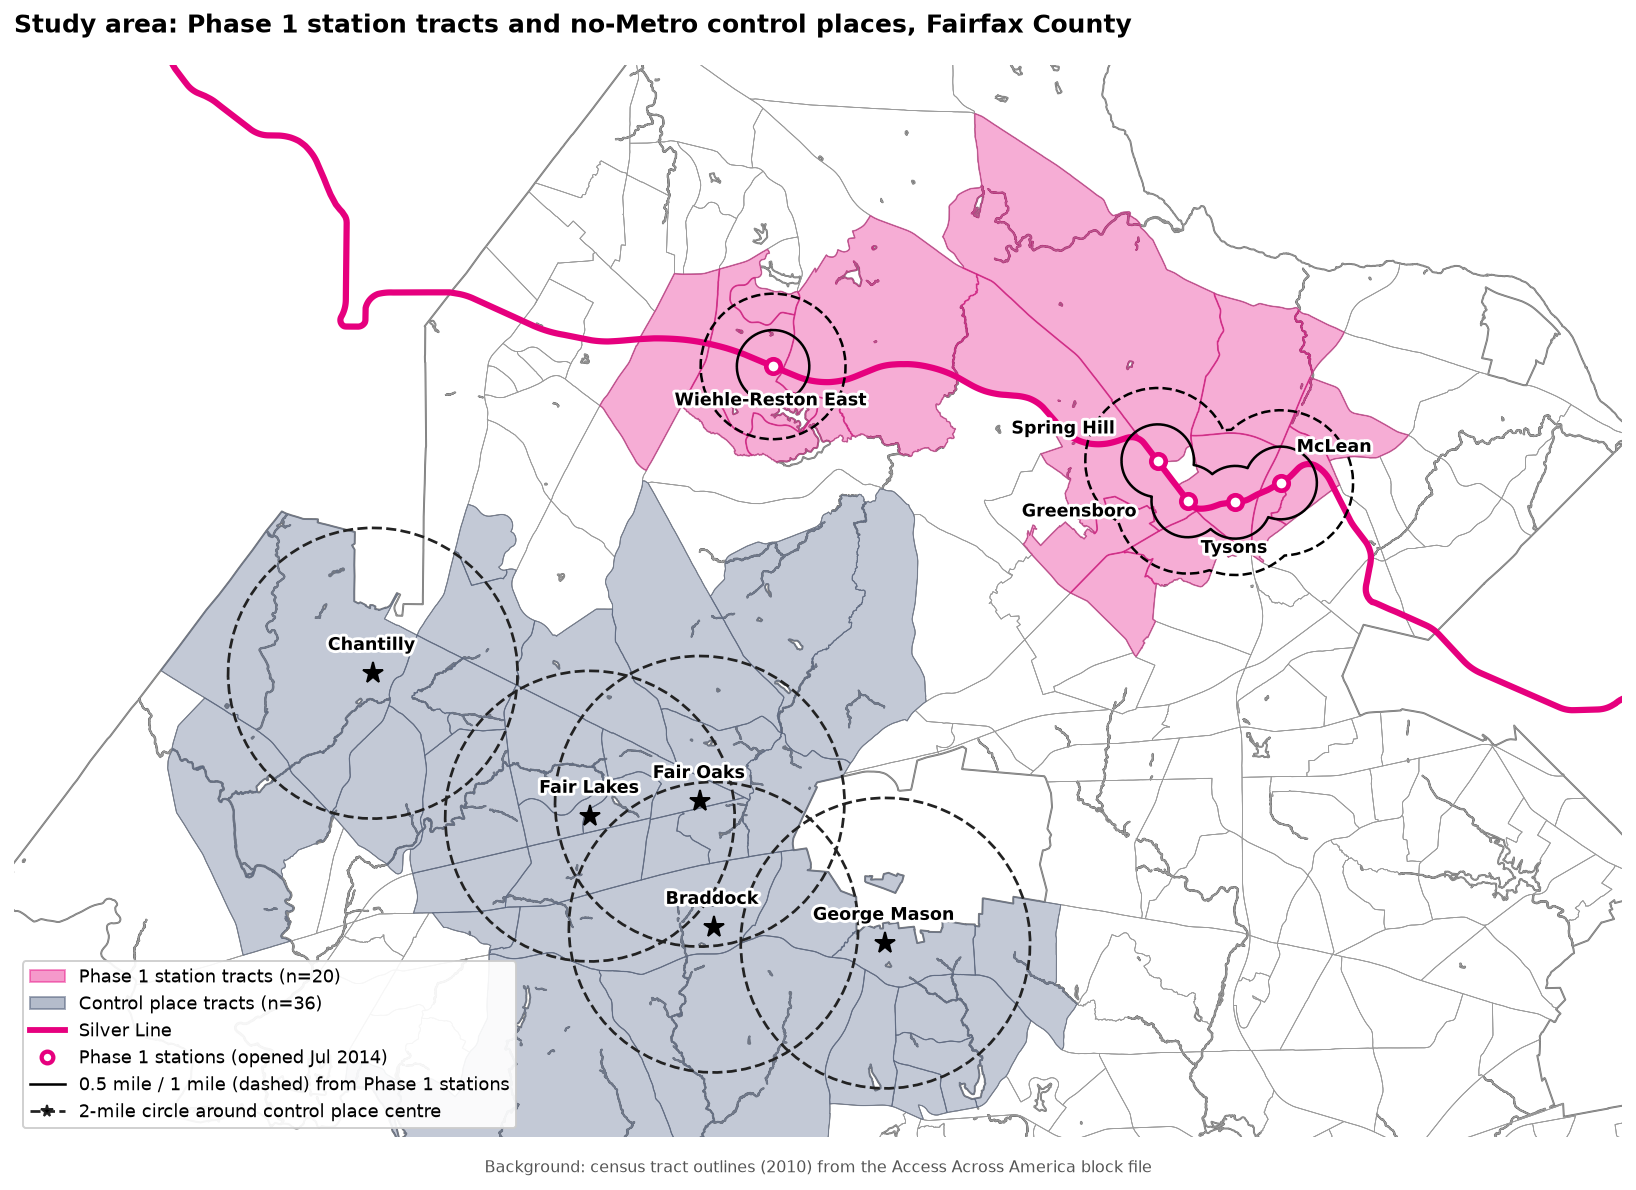

fig2_job_access_change_map.png


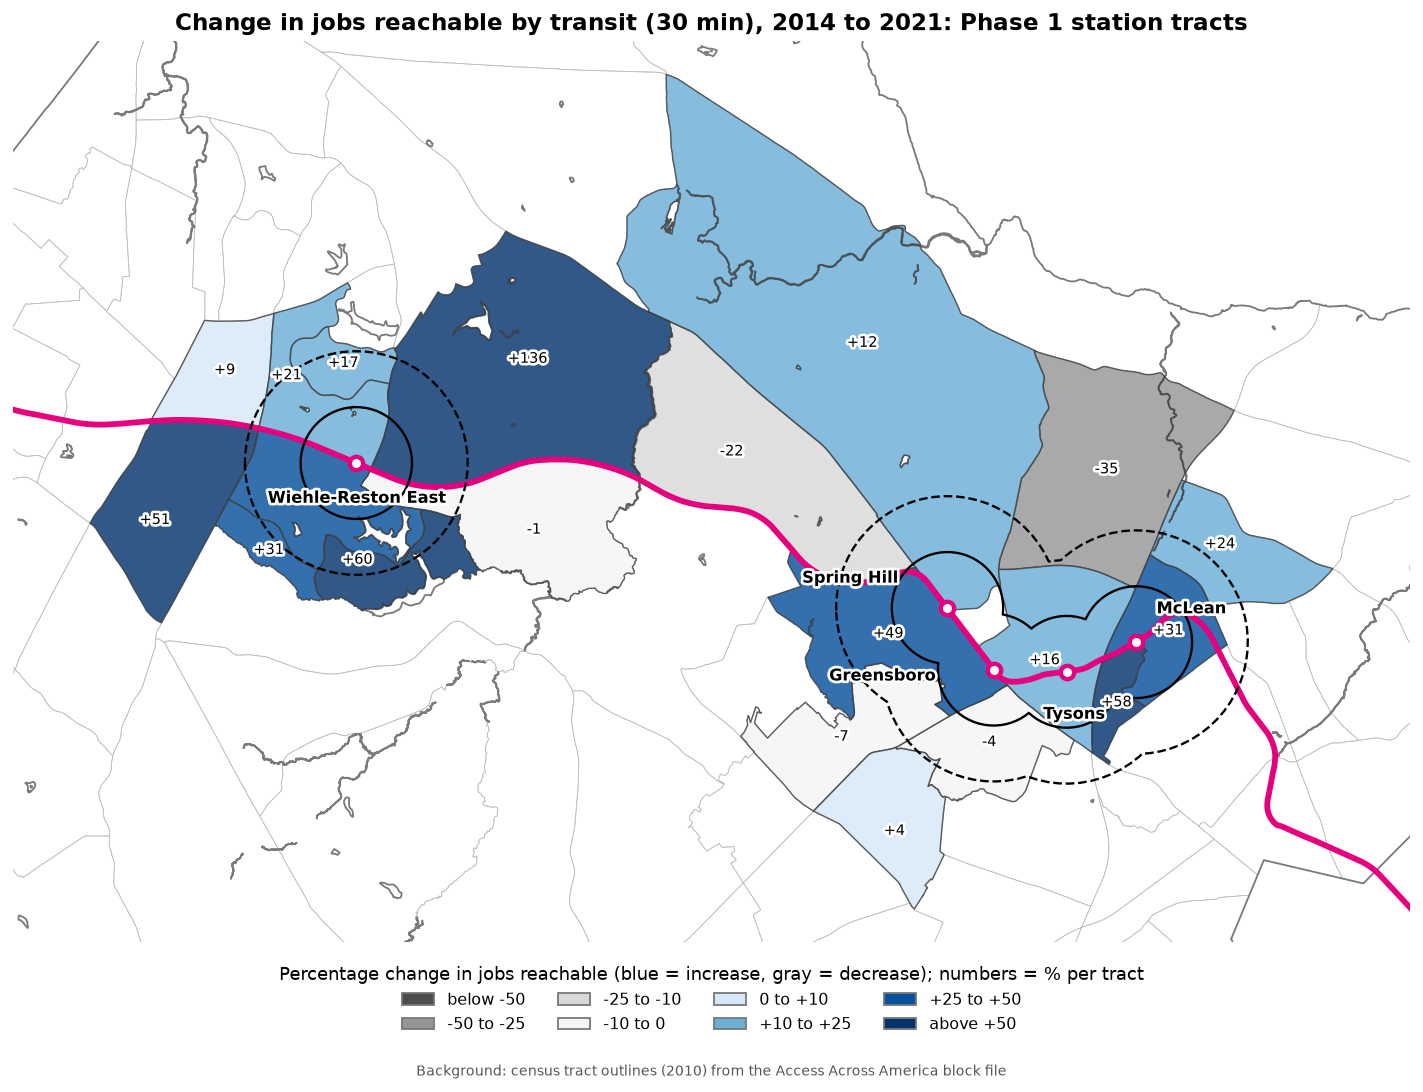

fig3_distance_bands_and_did.png


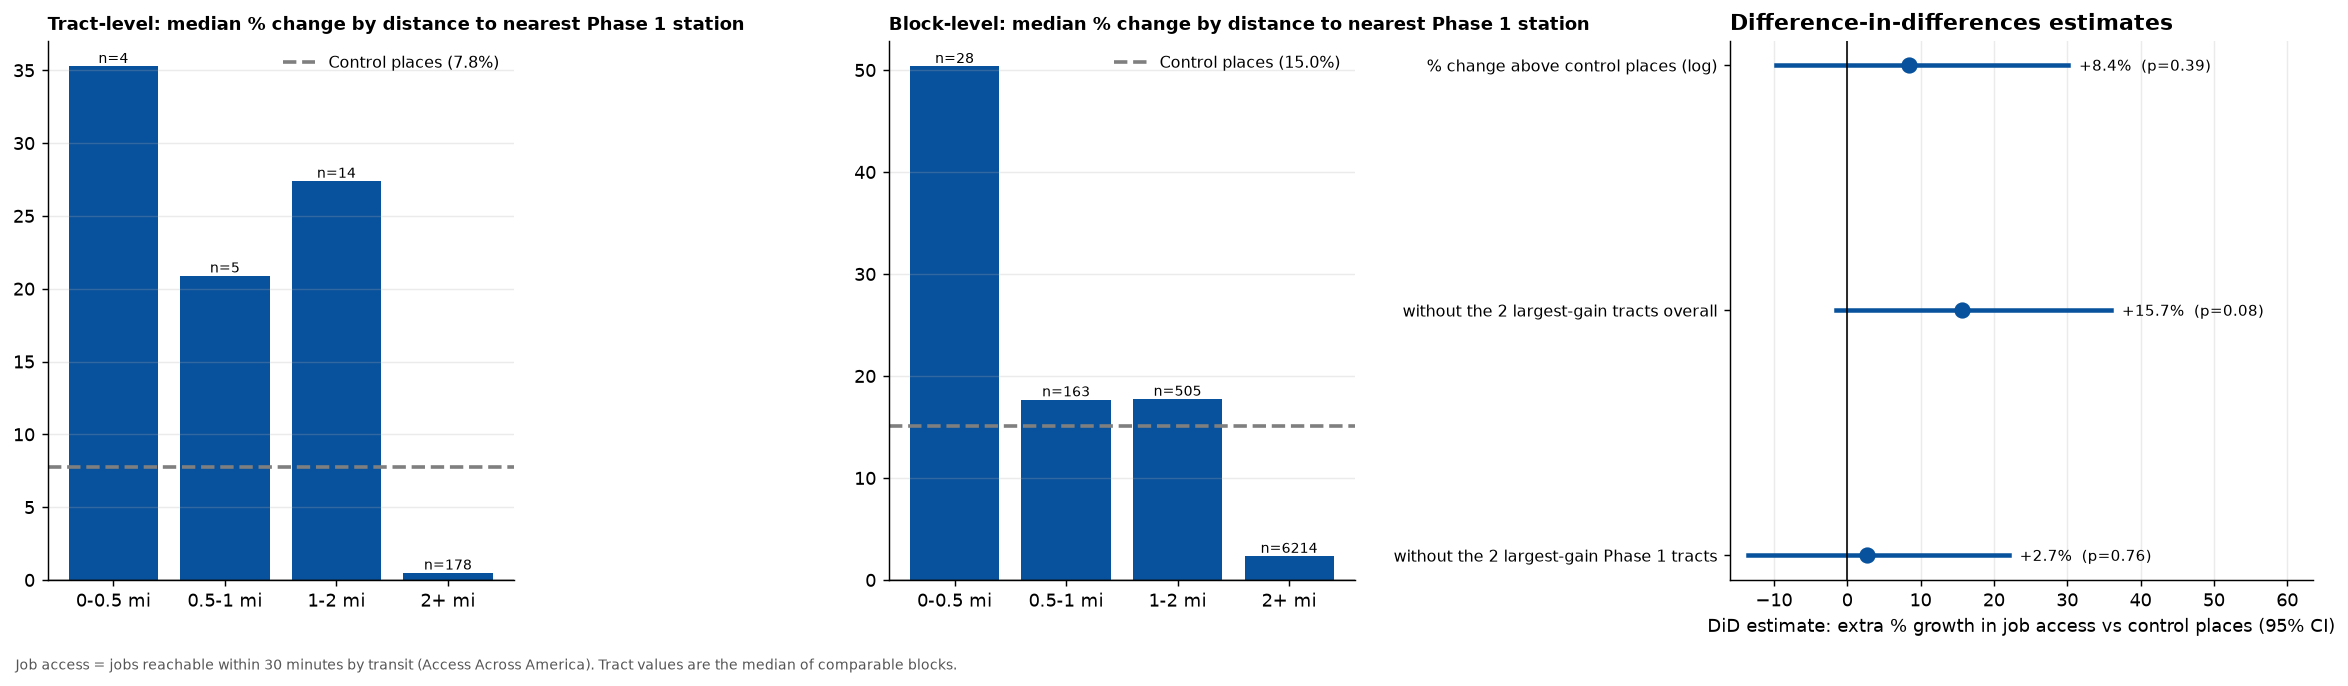

TABLE 2: difference-in-differences estimates


,Specification,Unit,Estimate,CI low,CI high,p-value,Tracts
0,"DiD, % change above control places (log)",%,8.398,-9.708,30.135,0.387,56
1,"DiD, extra jobs reachable per tract (levels)",jobs,4243.089,1840.714,6645.464,0.001,56
2,DiD (log) without the 2 largest-gain tracts ov...,%,15.681,-1.589,35.983,0.077,54
3,DiD (log) without the 2 largest-gain Phase 1 t...,%,2.729,-13.521,22.031,0.759,54


TABLE 5: distance bands


,Level,band,Units,Median_2014,Median_2021,Median_pct_change,Mean_pct_change
0,Tract,0-0.5 mi,4,28479.0,40788.8,35.3,36.1
1,Tract,0.5-1 mi,5,40257.0,47131.0,20.9,28.7
2,Tract,1-2 mi,14,17235.5,20221.2,27.4,45.7
3,Tract,2+ mi,178,4153.5,4026.0,0.5,9.7
4,Tract,Control places,36,3442.5,4585.0,7.8,21.8
5,Block,0-0.5 mi,28,42578.5,74801.0,50.4,80.3
6,Block,0.5-1 mi,163,26428.0,32848.0,17.7,387.3
7,Block,1-2 mi,505,11702.0,14661.0,17.7,142.9
8,Block,2+ mi,6214,3692.0,3846.0,2.3,70.7
9,Block,Control places,782,4502.0,6783.0,15.0,195.2


In [47]:
from IPython.display import Image, display
for f in ["fig1_study_area_map.png", "fig2_job_access_change_map.png", "fig3_distance_bands_and_did.png"]:
    print(f); display(Image(filename=os.path.join(OUT_DIR, f)))
print("TABLE 2: difference-in-differences estimates"); display(tab2.round(3))
print("TABLE 5: distance bands"); display(tab5.round(1))

## 16. Save outputs

In [48]:
for name, t in (("table1_descriptives", tab1), ("table1b_change", chg), ("table2_did_estimates", tab2),
                ("table3_station_did", tab3), ("table4_control_places", tab4), ("table5_distance_bands", tab5)):
    t.round(3).to_csv(os.path.join(OUT_DIR, name + ".csv"), index=False)
with pd.ExcelWriter(os.path.join(OUT_DIR, "statistical_tables_q1.xlsx")) as xw:
    for name, t in (("1 Descriptives", tab1), ("1b Change", chg), ("2 DiD", tab2), ("3 By station", tab3),
                    ("4 Control places", tab4), ("5 Distance bands", tab5)):
        t.round(3).to_excel(xw, sheet_name=name, index=False)
print("Saved outputs to:", os.path.abspath(OUT_DIR))

Saved outputs to: c:\Users\pkmu004\Documents\transit-buildout-analysis\analysis\outputs_q1
